# Stability of the steady oscillation with the one-point outlet temperature $T_{out}$

The companion of `limit_cycle_stability.ipynb` for the version of the write-up in which the outflow is carried at the one temperature

$$T_{out} = \bar T\left(\frac{P^*}{\bar P}\right)^{\varepsilon}, \qquad P^* = P_{out} + \frac{\Delta P_{max}}{3},$$

the CV temperature at the pressure where the outlet reed passes the most gas, instead of the adiabatic $T(\psi)$ inside the Fourier integrals. Everything else is as in that notebook: the energy-consistent $\delta^2$ term of (26) (factor $1 - 1/\gamma_E$), the reed law with its backflow branch, and the full simulation unchanged as the reference. In the averaged model $T_{out}$ is a constant over the cycle, so it enters the analysis as one weight $\theta = T_{out}/T_{in}$ on the outlet's slope: the gain is $X = 2\langle(\tilde h_{in} + \theta\tilde h_{out})\sin^2\psi\rangle$, its amplitude derivative $2\langle(\tilde h_{in} + \theta\tilde h_{out})\cos 2\psi\rangle$, and the mass-balance slope $X_0 = \langle\tilde h_{in} + \tilde h_{out}\rangle$ is unchanged.

Three cells: the model (`mode='Tout'` is the default; `'Tbar'` and `'exact'` are kept for comparison); the fixed point, the three closed-form rates and the Jacobian; the return after an amplitude perturbation against the full simulation, and the edge of the basin with the budget (33) carrying $\theta$. The numbers are those quoted in section 10 of the $T_{out}$ write-up.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp, quad
from scipy.optimize import fsolve, brentq
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
def style(ax):
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)


BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4,
            mode='Tout', corr=True, backflow=True)


class Model:
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.eps = self.R / (self.cv + self.R)
        self.fac = (1.0 - 1.0 / self.gamma_E) if self.corr else 1.0
        self.Pstar = self.P_out + self.dP_max / 3.0
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI); self.SPS = np.sin(self.PSI)

    def theta(self, Pb):
        """T_out / T_bar = (P*/P_bar)^eps of mode 'Tout' (1 in mode 'Tbar')."""
        return (self.Pstar / Pb) ** self.eps if self.mode == 'Tout' else 1.0

    # ---------- reed law ----------
    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo])
        if self.backflow:
            mr = dP <= 0; out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def slope(self, dP, h=1.0):
        return (self.reed(dP + h) - self.reed(dP - h)) / (2 * h)

    def slope_vec(self, dP):
        """Local slope d mdot / d(Delta P): m_max/dP_max * (1 - 3u) / (2 sqrt|u|) on both branches, 0 once shut."""
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        m = (u < 1) & (u != 0)
        if not self.backflow:
            m &= u > 0
        out[m] = self.m_max / self.dP_max * (1 - 3 * u[m]) / (2 * np.sqrt(np.abs(u[m])))
        return out

    # ---------- full model ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def y0_full(self):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        return np.array([self.x0, self.v0, M0, self.cv * M0 * self.T0])

    def simulate(self, y0, t0, t1, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Full model from state y0 at t0 to t1, in chunks; once the oscillation is dead and the mean has landed on P_in or
        P_out (a stiff, expensive tail), the rest is filled with the frozen state.  Returns t and the state arrays."""
        y = np.array(y0, dtype=float); ts, ys = [], []; ta = t0
        while ta < t1 - 1e-9:
            tb = min(ta + chunk, t1)
            te = ta + np.arange(0.0, tb - ta, 1.0 / fs); te = np.append(te[te < tb - 1e-9], tb)
            sol = solve_ivp(self.full_ode, (ta, tb), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            ts.append(sol.t[:-1]); ys.append(sol.y[:, :-1]); y = sol.y[:, -1]; ta = tb
            x, v, M, E = sol.y; P = M * self.R * (E / (self.cv * M)) / (self.V0_cv + x * self.A_neck)
            tail = sol.t > tb - 0.05
            landed = min(np.abs(P[tail] - self.P_in).max(), np.abs(P[tail] - self.P_out).max()) < 20.0
            if landed and np.abs(v[tail]).max() < 1e-3:
                tr = np.arange(tb, t1, 1.0 / fs); ts.append(tr); ys.append(np.repeat(y[:, None], tr.size, axis=1)); break
        t = np.concatenate(ts); Y = np.concatenate(ys, axis=1)
        return t, Y

    def PT_of(self, Y):
        x, v, M, E = Y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
        return P, T

    def run_full(self, t_end, **kw):
        t, Y = self.simulate(self.y0_full(), 0.0, t_end, **kw); P, T = self.PT_of(Y)
        return t, P, T

    @staticmethod
    def perturb_state(t, Y, eta):
        """Scale the oscillating part of (x, v, E) over the last cycle by eta, keeping M and the cycle means: the state
        at the end of Y with its oscillation amplitude multiplied by eta and its mean unchanged."""
        x, v, M, E = Y
        up = np.where((v[:-1] < 0) & (v[1:] >= 0))[0]
        a, b = up[-2], up[-1]                                    # last full cycle between upward zero crossings of v
        xb, Eb = x[a:b].mean(), E[a:b].mean()
        return np.array([xb + eta * (x[-1] - xb), eta * v[-1], M[-1], Eb + eta * (E[-1] - Eb)])

    # ---------- averaged model ----------
    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def inlet(self, Pb, delta):
        """Inlet rectified flow F0_in and gain N_in = F1_in/delta (own-drop convention: positive = damping)."""
        if delta > 1.0:
            vals = self.reed_vec(self.P_in - Pb + delta * self.CPS)
            return vals.mean(), 2.0 * (vals * self.CPS).mean() / delta
        return self.reed(self.P_in - Pb), self.slope(self.P_in - Pb)

    def outlet(self, Pb, Tb, delta):
        """Outlet rectified flow F0_out, enthalpy-weighted flow H0 = <mdot_out T> and gain G = H1/delta."""
        mode = self.mode
        if delta > 1.0:
            P = Pb + delta * self.CPS; vals = self.reed_vec(P - self.P_out); F0 = vals.mean()
            if mode == 'exact':
                T = Tb * (P / Pb) ** self.eps
                return F0, (vals * T).mean(), 2.0 * (vals * T * self.CPS).mean() / delta
            Tw = Tb * self.theta(Pb)                                   # T_bar, or T_out in mode 'Tout'
            return F0, Tw * F0, Tw * 2.0 * (vals * self.CPS).mean() / delta
        F0 = self.reed(Pb - self.P_out); s = self.slope(Pb - self.P_out)
        if mode == 'exact':
            return F0, Tb * F0, Tb * s + F0 * self.eps * Tb / Pb
        Tw = Tb * self.theta(Pb)
        return F0, Tw * F0, Tw * s

    def rates(self, Pb, Tb, delta):
        Vp, Vc, kcv, kp, w = self.geom(Pb)
        F0i, Ni = self.inlet(Pb, delta); F0o, H0o, Go = self.outlet(Pb, Tb, delta)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Go)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dMb = F0i - F0o
        dPb = (self.Cf * (self.T_in * F0i - H0o) - self.fac * Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        return lam, g, dMb, dPb, w

    def state(self, y):
        """(T_bar, delta) of a slow state y = (M_bar, P_bar, a)."""
        Mb, Pb, a = y; Vp, Vc, kcv, kp, w = self.geom(Pb)
        return Pb * Vc / (Mb * self.R), kcv * max(a, 0.0) / self.A_neck

    def slow_rhs(self, t, y):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        lam, g, dMb, dPb, w = self.rates(Pb, Tb, delta)
        dPp = 1e-4 * max(abs(dPb), 1.0); wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [dMb, dPb, da]

    def y0_avg(self):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        return np.array([M0, self.P0, self.v0 / w0])

    def run_avg(self, t_end, y0=None, t0=0.0, chunk=0.25, max_step=2e-3):
        """Slow ODEs from y0 (default: the kicked initial state) in chunks, stopping once the amplitude has died and the
        mean has landed within 50 Pa of P_in or P_out; after that the state is frozen."""
        y = np.array(self.y0_avg() if y0 is None else y0, dtype=float); ta = t0; sols = []

        def landed(t, yy):
            Mb, Pb, a = yy
            if self.geom(Pb)[2] * max(a, 0.0) / self.A_neck > 10.0:
                return 1e3
            return min(self.P_in - Pb, Pb - self.P_out) - 50.0
        landed.terminal = True; landed.direction = -1
        while ta < t_end - 1e-9:
            tb = min(ta + chunk, t_end)
            sol = solve_ivp(self.slow_rhs, (ta, tb), y, method='LSODA', events=landed, rtol=1e-9, atol=[1e-13, 1e-4, 1e-12],
                            dense_output=True, max_step=max_step)
            sols.append(sol); y = sol.y[:, -1]; ta = sol.t[-1]
            if sol.status == 1:
                break
        return AvgSol(sols, y)

    def observe(self, sol, ta):
        Mb, Pb, a = sol.sol(ta)
        g = np.array([self.geom(p) for p in np.atleast_1d(Pb)])
        return Pb, g[:, 2] * np.maximum(a, 0) / self.A_neck, Pb * g[:, 1] / (Mb * self.R)

    # ---------- the steady oscillation as a fixed point ----------
    def fixed_point(self, t_guess=3.0):
        y = self.run_avg(t_guess).sol(t_guess - 1e-3)
        ys = fsolve(lambda z: np.array(self.slow_rhs(0.0, z)) * [1e5, 1e-2, 1e3], y, xtol=1e-13)
        return ys

    def jacobian(self, y, hM=1e-3, hP=100.0, ha=1e-2):
        """Central-difference Jacobian of the slow right-hand side at y, in (M_bar, P_bar, a) coordinates.  The steps are
        large against the spacing of the phase grid in pressure (about 130 Pa at the steady swing), because the derivative
        of the grid sums only approximates the derivative of the integrals when the step averages over the grid."""
        J = np.zeros((3, 3)); y = np.array(y, dtype=float)
        for j, h in enumerate([hM * y[0], hP, ha * y[2]]):
            yp, ym = y.copy(), y.copy(); yp[j] += h; ym[j] -= h
            J[:, j] = (np.array(self.slow_rhs(0.0, yp)) - np.array(self.slow_rhs(0.0, ym))) / (2 * h)
        return J

    # ---------- cycle averages of the local reed slope (the closed forms) ----------
    def slope_local(self, psi, Pb, Tb, delta):
        """Local slopes along the cycle at phase psi: s_in = d mdot_in/d(Delta P_in) and
        s_out = d(mdot_out T)/d(Delta P_out) / T_bar (T = T_bar in mode 'Tbar')."""
        P = Pb + delta * np.cos(psi)
        s_in = self.slope_vec(self.P_in - P); s_out = self.slope_vec(P - self.P_out)
        if self.mode == 'exact':
            T = (P / Pb) ** self.eps
            s_out = T * (s_out + self.eps * self.reed_vec(P - self.P_out) / P)
        else:
            s_out = self.theta(Pb) * s_out                             # T_out/T_bar weights the outlet's slope (1 in 'Tbar')
        return s_in, s_out

    def slope_averages_fine(self, Pb, Tb, delta, n=2 ** 21):
        """Same averages as slope_averages on a fine uniform phase grid (the local slope has integrable 1/sqrt|u|
        singularities where a reed opens or reverses, which a coarse grid undersamples)."""
        psi = (np.arange(n) + 0.5) * (2 * np.pi / n)
        s_in, s_out = self.slope_local(psi, Pb, Tb, delta)
        s2 = 2 * np.sin(psi) ** 2; c2 = 2 * np.cos(2 * psi)
        return {'in': (s_in.mean(), (s_in * s2).mean(), (s_in * c2).mean()), 'out': (s_out.mean(), (s_out * s2).mean(), (s_out * c2).mean())}

    def slope_averages_quad(self, Pb, Tb, delta):
        """Same averages as slope_averages, by adaptive quadrature with break points where a reed opens, shuts or
        reverses (the slope has integrable 1/sqrt|u| singularities there)."""
        from scipy.integrate import quad
        pts = []
        for lo, sgn in ((self.P_in - Pb, -1.0), (Pb - self.P_out, 1.0)):      # u = 0 and u = 1 of each reed
            for val in (0.0, self.dP_max):
                c = (val - lo) / (sgn * delta)
                if -1.0 < c < 1.0:
                    pts.append(np.arccos(c))
        pts = sorted(pts)
        out = {}
        for k in ('in', 'out'):
            res = []
            for w in (lambda p: 1.0, lambda p: 2.0 * np.sin(p) ** 2, lambda p: 2.0 * np.cos(2 * p)):
                f = lambda p: self.slope_local(np.array([p]), Pb, Tb, delta)[0 if k == 'in' else 1][0] * w(p)
                res.append(quad(f, 0.0, np.pi, points=pts or None, limit=400)[0] / np.pi)
            out[k] = tuple(res)
        return out

    def slope_averages(self, Pb, Tb, delta):
        """At (P_bar, T_bar, delta): the local slope of the inlet flow and of the outlet enthalpy flux around the cycle,
        averaged with weights 1, 2 sin^2 psi and cos 2 psi.  Returns a dict with, for 'in' and 'out', the triple
        (<s>, 2<s sin^2>, 2<s cos 2psi>) where s_in = d mdot_in/d(Delta P_in) and s_out = d(mdot_out T)/d(Delta P_out)/T_bar."""
        P = Pb + delta * self.CPS
        s_in = self.slope_vec(self.P_in - P)
        s_out = self.slope_vec(P - self.P_out)
        if self.mode == 'exact':
            T = (P / Pb) ** self.eps                                   # T(psi)/T_bar
            s_out = T * (s_out + self.eps * self.reed_vec(P - self.P_out) / P)
        else:
            s_out = self.theta(Pb) * s_out
        c2 = np.cos(2 * self.PSI); s2 = self.SPS ** 2
        out = {}
        for k, s in (('in', s_in), ('out', s_out)):
            out[k] = (s.mean(), 2 * (s * s2).mean(), 2 * (s * c2).mean())
        return out


class AvgSol:
    """Dense output over the chunks; after the last chunk the state is frozen."""

    def __init__(self, sols, y_last):
        self.sols = sols; self.y_last = np.asarray(y_last); self.t_last = sols[-1].t[-1]; self.t_first = sols[0].t[0]

    def sol(self, ta):
        ta = np.atleast_1d(np.asarray(ta, dtype=float)); out = np.empty((3, ta.size))
        for j, tt in enumerate(ta):
            if tt >= self.t_last:
                out[:, j] = self.y_last; continue
            if tt <= self.t_first:
                out[:, j] = self.sols[0].sol(self.t_first); continue
            for s_ in self.sols:
                if s_.t[0] <= tt <= s_.t[-1]:
                    out[:, j] = s_.sol(tt); break
        return out if out.shape[1] > 1 else out[:, 0]


def per_cycle(model, t, P, T=None):
    """Per-cycle time, mean pressure, half swing (and mean temperature) of a simulated pressure trace."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    if n < 2:
        return [np.array([]) for _ in range(4)]
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        rows.append((0.5 * (a + b), P[m].mean(), 0.5 * (P[m].max() - P[m].min()), T[m].mean() if T is not None else np.nan))
    return [np.array(c) for c in zip(*rows)]


SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))

## 1. The fixed point, the three averages and the Jacobian

`fixed_point` solves the three slow equations with a root finder started from a 3 s run. For identical reeds the mass balance puts $\bar P^* = P_b = (P_{in} + P_{out})/2$ exactly (the pure cosine gives the two reeds mirror-image swings); $\lambda = 0$ fixes $\delta^*$ and $d\bar P/dt = 0$ fixes $\bar T^*$. With $T_{out}$ the outlet terms depend on $\bar T$ only through $T_{out} = \theta\bar T$, so the fixed point has the same $\bar P^*$ and $\delta^*$ as with $\bar T$ at the outlet and a mean temperature higher by the factor $1/\theta$.

The cell checks the closed forms against the model's own integrals (the gain from $2\langle s\sin^2\psi\rangle$, its amplitude derivative from $2\langle s\cos 2\psi\rangle$ against a finite difference, the mass-balance slope from $\langle s\rangle$), evaluates $\Lambda$, $X^*$, $X(\delta^*)$, $\delta \partial X/\partial\delta$ and $X_0$ on a fine phase grid (the slope has integrable $1/\sqrt{|u|}$ singularities where a reed opens or reverses), and compares the three rates $\sigma_a = \Lambda\delta \partial X/\partial\delta$, $\sigma_P = (\Lambda/\kappa)X_0$ and $\sigma_T = -\dot m_{0,out}/\bar M$ with the eigenvalues of the finite-difference Jacobian — for the model as set up, without the backflow branch, and with $\bar T$ and with the adiabatic $T(\psi)$ at the outlet.

In [2]:
def fine_psi(n=2 ** 18):
    return (np.arange(n) + 0.5) * (2 * np.pi / n)

def mass_slope_fine(m, Pb, delta, n=2 ** 18):
    """X_0 = <h_in + h_out>: the slope of the net rectified inflow in units of c_1 mdot_max / 2 dP_max."""
    P = Pb + delta * np.cos(fine_psi(n)); unit = m.m_max / (2 * m.dP_max)
    return -(m.slope_vec(m.P_in - P).mean() + m.slope_vec(P - m.P_out).mean()) / unit

def net_flow_fine(m, Pb, delta, n=2 ** 18):
    P = Pb + delta * np.cos(fine_psi(n))
    return (m.reed_vec(m.P_in - P) - m.reed_vec(P - m.P_out)).mean()

def closed_forms(m, ys):
    """Lambda, X*, and at the fixed point: X, delta dX/ddelta (the outlet's weight included) and X_0."""
    Tb, dl = m.state(ys); Vp, Vc, kcv, kp, w = m.geom(ys[1]); f = kcv / (kcv + kp)
    unit = m.m_max / (2 * m.dP_max); Lam = 0.5 * f * (m.Cf * m.T_in / Vc) * unit
    sa = m.slope_averages_fine(ys[1], Tb, dl)
    X = -(sa['in'][1] + sa['out'][1] * Tb / m.T_in) / unit; dX = -(sa['in'][2] + sa['out'][2] * Tb / m.T_in) / unit
    return dict(Lam=Lam, Xstar=m.b_gas / (2 * m.m_gas * Lam), X=X, dX=dX, X0=mass_slope_fine(m, ys[1], dl),
                kappa=m.gamma_E * Vp / (2 * m.gamma * Vc), f=f, unit=unit, sa=sa)

rows = []; fixed = {}
for kw, lab in [(dict(), 'T_out (model as set up)'), (dict(backflow=False), 'T_out, one-sided law (6)'), (dict(mode='Tbar'), 'T_bar at the outlet'), (dict(mode='exact'), 'adiabatic T(psi)')]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); Vp, Vc, kcv, kp, w = m.geom(ys[1]); fixed[lab] = (m, ys)
    cf = closed_forms(m, ys); sa = cf['sa']; lam, g, dMb, dPb, w = m.rates(ys[1], Tb, dl)
    g_formula = -(m.Cf / Vc) * (m.T_in * sa['in'][1] + Tb * sa['out'][1]); dg_formula = -(m.Cf / Vc) * (m.T_in * sa['in'][2] + Tb * sa['out'][2])
    h = 0.01 * dl; dg_fd = (m.rates(ys[1], Tb, dl + h)[1] - m.rates(ys[1], Tb, dl - h)[1]) / (2 * h) * dl
    hP = 20.0; sM_fd = (net_flow_fine(m, ys[1] + hP, dl) - net_flow_fine(m, ys[1] - hP, dl)) / (2 * hP)
    P = ys[1] + dl * np.cos(fine_psi(2 ** 16)); ui = (m.P_in - P) / m.dP_max; uo = (P - m.P_out) / m.dP_max
    F0o = m.outlet(ys[1], Tb, dl)[0]; J = m.jacobian(ys); ev = np.sort(np.linalg.eigvals(J).real)
    rows.append({'': lab, 'P_bar* [bar]': ys[1] / 1e5, 'delta* [bar]': dl / 1e5, 'T_bar* [K]': Tb, 'T_out* [K]': Tb * m.theta(ys[1]), 'M_bar* [g]': ys[0] * 1e3,
                 'reed shut [fraction of the cycle]': (uo >= 1).mean(), 'reed reversed': (uo <= 0).mean(),
                 'g from (16) [1/s]': g, 'g from 2<s sin^2 psi> [1/s]': g_formula,
                 'delta dg/ddelta, finite difference [1/s]': dg_fd, 'delta dg/ddelta from 2<s cos 2psi> [1/s]': dg_formula,
                 'dF_M/dP, finite difference [g/s per bar]': sM_fd * 1e8, 'the same from <s> [g/s per bar]': cf['unit'] * cf['X0'] * 1e8,
                 'Lambda [1/s]': cf['Lam'], 'X* = b/(2 m Lambda)': cf['Xstar'], 'X(delta*)': cf['X'], 'X(P*, 0)': -(m.slope(m.P_in - ys[1]) + m.theta(ys[1]) * Tb / m.T_in * m.slope(ys[1] - m.P_out)) / cf['unit'],
                 'delta dX/ddelta at delta*': cf['dX'], 'X_0 at delta*': cf['X0'], 'kappa': cf['kappa'],
                 'sigma_a = Lambda delta dX/ddelta [1/s]': cf['Lam'] * cf['dX'], 'J_aa [1/s]': J[2, 2],
                 'sigma_P = (Lambda/kappa) X_0 [1/s]': cf['Lam'] / cf['kappa'] * cf['X0'], 'J_PP [1/s]': J[1, 1],
                 'sigma_T = -m0_out/M [1/s]': -F0o / ys[0], 'eigenvalue 1 [1/s]': ev[0], 'eigenvalue 2 [1/s]': ev[1], 'eigenvalue 3 [1/s]': ev[2]})
pd.set_option('display.width', 200)
display(pd.DataFrame(rows).set_index('').T.round(4))
m, ys = fixed['T_out (model as set up)']; J = m.jacobian(ys); ev, V = np.linalg.eig(J)
print('Jacobian of the model as set up (rows dM/dt, dP/dt, da/dt; columns M, P, a):'); print(np.array2string(J, precision=4, suppress_small=True))
for i in np.argsort(ev.real):
    v = np.real(V[:, i]) / np.array(ys); v = v / v[np.argmax(np.abs(v))]
    print('mode at %.3f 1/s: (dM/M, dP/P, da/a) = %s' % (ev[i].real, np.array2string(v, precision=4, suppress_small=True)))

,T_out (model as set up),"T_out, one-sided law (6)",T_bar at the outlet,adiabatic T(psi)
P_bar* [bar],5.7250,5.7250,5.7250,5.7250
delta* [bar],0.2947,0.3339,0.2947,0.2947
T_bar* [K],299.8711,299.2163,298.0751,299.0528
T_out* [K],298.0751,297.4242,298.0751,299.0528
M_bar* [g],0.6611,0.6625,0.6651,0.6629
reed shut [fraction of the cycle],0.2863,0.3150,0.2863,0.2863
reed reversed,0.1171,0.1920,0.1171,0.1170
g from (16) [1/s],5.0135,5.0135,5.0135,5.0135
g from 2<s sin^2 psi> [1/s],5.0192,5.0366,5.0192,5.0163
"delta dg/ddelta, finite difference [1/s]",-80.1720,-18.4163,-80.1720,-79.4611


Jacobian of the model as set up (rows dM/dt, dP/dt, da/dt; columns M, P, a):
[[       0.           -0.            0.    ]
 [83379216.7618      -11.6544   272465.3929]
 [     -16.4117        0.          -26.647 ]]
mode at -26.650 1/s: (dM/M, dP/P, da/a) = [-0.0004 -0.0004  1.    ]
mode at -11.448 1/s: (dM/M, dP/P, da/a) = [1.     0.4717 0.2015]
mode at -0.204 1/s: (dM/M, dP/P, da/a) = [ 1.      0.0084 -0.029 ]


## 2. Perturbing the steady oscillation, and the edge of the basin

**Small perturbations.** The full simulation is run to 1.5 s, by which time it is on its steady oscillation, and the oscillating part of its state is scaled by $\eta$ (`perturb_state`: $x$, $v$ and $E$ about their last-cycle means, $M$ unchanged — the sealed-cycle relations are linear, so this changes the swing and nothing else). The per-cycle half swing afterwards is compared with $\delta(t)$ of the averaged model started from $\eta a^*$ at its fixed point, and the rate of return is fitted to $\ln|\delta - \delta_\infty|$ while the deviation decays from a half to a twentieth of its initial value, against $\sigma_a$ of the previous cell. The same without the backflow branch.

**Large perturbations.** The smallest surviving fraction $\eta$ by bisection: in the averaged model from its own fixed point and from a state with the simulation's mean pressure and temperature, and in the full simulation. The budget (33) with $\theta$ — $\dot m_{net} = \dot m_{in} - \theta\dot m_{out}$ in the logarithm and in the drift time, the piston damping, and the $\theta$ integral — gives $\delta^* e^{-B}$ from the simulated mean and from 1 mbar below $P_b$. With $T_{out}$ the drift (31) at $\delta = 0$ balances not at $P_b$ but where $\dot m_{in} = \theta\dot m_{out}$, 0.8 mbar below it; the last line gives that pressure.

== T_out, with backflow: fixed point delta* 0.2947 bar, P* 5.7250, T* 299.87 K, J_aa -26.65, eigenvalues [-26.65005904 -11.44768636  -0.20367561]; simulation at 1.5 s: delta 0.2946 bar, mean 5.7162 bar, T 299.27 K  [6 s]


   eta 0.5: swing at 100 ms sim 0.2561 avg 0.2571 bar (max |sim-avg| over the run 1.58 mbar); mean P change at 100 ms sim -6.9 avg -0.1 mbar; return rate sim -25.2 avg -26.2 1/s


   eta 0.8: swing at 100 ms sim 0.2902 avg 0.2904 bar (max |sim-avg| over the run 0.61 mbar); mean P change at 100 ms sim +0.0 avg -0.1 mbar; return rate sim -28.3 avg -28.1 1/s


   eta 0.9: swing at 100 ms sim 0.2927 avg 0.2928 bar (max |sim-avg| over the run 0.54 mbar); mean P change at 100 ms sim +0.3 avg -0.1 mbar; return rate sim -26.8 avg -27.2 1/s


   eta 1.1: swing at 100 ms sim 0.2971 avg 0.2972 bar (max |sim-avg| over the run 0.30 mbar); mean P change at 100 ms sim -0.2 avg +0.1 mbar; return rate sim -26.8 avg -26.0 1/s


...

   eta 3.0: swing at 100 ms sim 0.8659 avg 0.8575 bar (max |sim-avg| over the run 12.55 mbar); mean P change at 100 ms sim +17.7 avg +0.0 mbar; return rate sim -3.6 avg -3.6 1/s


   basin: averaged from its fixed point eta 0.0168-0.0174 (5.7 mbar); averaged from the simulated mean 0.111-0.114 (37.5 mbar); full simulation 0.147-0.152 (50.0 mbar)  [183 s]


   budget from simulated mean 5.7115 bar: closes at 5.5417 bar after t1 = 0.29 s; log 2.51, damping -0.49, temperature -0.021 -> B = 2.00 -> survives down to delta* e^-B = 45.4 mbar (eta 0.136)


   budget from 1 mbar below P_b 5.7240 bar: closes at 5.5417 bar after t1 = 0.75 s; log 6.73, damping -1.26, temperature -0.049 -> B = 5.42 -> survives down to delta* e^-B = 1.5 mbar (eta 0.004)


   P_b = 5.72500 bar; the theta-weighted net inflow (31) vanishes at 5.72418 bar (0.8 mbar below P_b)


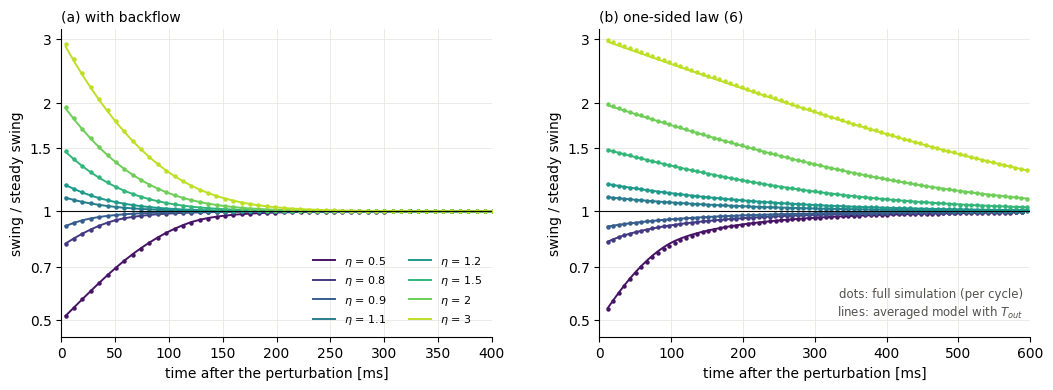

In [3]:

ETAS = [0.5, 0.8, 0.9, 1.1, 1.2, 1.5, 2.0, 3.0]; T_P = 1.5; T_AFTER = 0.6; T_LONG = 3.0


def fit_rate(t, d, d_inf, lo=0.5, hi=0.05):
    dev = np.abs(d - d_inf); dev0 = dev[0]
    sel = (dev < lo * dev0) & (dev > hi * dev0)
    if (dev < hi * dev0).any():
        sel &= np.arange(len(t)) < np.argmax(dev < hi * dev0)
    return np.polyfit(t[sel], np.log(dev[sel]), 1)[0] if sel.sum() >= 3 else np.nan


def survives_sim(m, t, Y, eta):
    yp = m.perturb_state(t, Y, eta); t2, Y2 = m.simulate(yp, T_P, T_P + T_LONG); P2, T2 = m.PT_of(Y2)
    tm2, Pm2, half2, Tm2 = per_cycle(m, t2, P2, T2); late = tm2 > T_P + T_LONG - 0.2
    return bool(late.any() and half2[late].mean() > 1e4)


def survives_avg(m, y_start, eta):
    y0 = y_start.copy(); y0[2] *= eta; sol = m.run_avg(T_LONG, y0=y0)
    return bool(m.observe(sol, np.array([T_LONG - 1e-3]))[1][0] > 1e4)


def bisect_eta(test, lo, hi, ratio=1.04):
    assert not test(lo) and test(hi)
    while hi / lo > ratio:
        mid = np.sqrt(lo * hi); lo, hi = (lo, mid) if test(mid) else (mid, hi)
    return lo, hi


def budget_from(m, P0, Pgeom):
    """B of (33) with theta: drive kappa ln(mnet_theta(P1)/mnet_theta(P0)) - damping - temperature integral; window closes
    where lambda_lin = 0 or a reed is pressed shut (scan in 1 Pa steps in the direction of the drift)."""
    c2 = m.gamma * m.R * m.T_in; Vp, Vc = m.geom(Pgeom)[0], m.geom(Pgeom)[1]
    f = m.gamma_E * Vp / (m.gamma_E * Vp + m.gamma * Vc); kappa = m.gamma_E * Vp / (2 * m.gamma * Vc); C = (Vc + (m.gamma_E / m.gamma) * Vp) / c2
    th = lambda p: m.theta(p)
    mnet = lambda p: m.reed(m.P_in - p) - th(p) * m.reed(p - m.P_out)
    lam_lin = lambda p: m.rates(p, m.T_in, 0.0)[0]
    step = 1.0 if mnet(P0) > 0 else -1.0; p = P0
    while lam_lin(p + step) > 0:
        p += step
    P1 = p + step; Pe = P1 - 0.5 * step
    drive = kappa * np.log(mnet(Pe) / mnet(P0))
    t1 = abs(C * quad(lambda q: 1.0 / mnet(q), P0, Pe, limit=400)[0])
    temp = abs(kappa * m.eps * quad(lambda q: th(q) * m.reed(q - m.P_out) / (q * mnet(q)), P0, Pe, limit=400)[0])
    return drive - m.b_gas / (2 * m.m_gas) * t1 - temp, P1, t1, drive, m.b_gas / (2 * m.m_gas) * t1, temp


tic = time.time()
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.0)); fig.subplots_adjust(wspace=0.25); cols = plt.cm.viridis(np.linspace(0.05, 0.9, len(ETAS)))
for jj, (kw, lab) in enumerate([(dict(), 'T_out, with backflow'), (dict(backflow=False), 'T_out, one-sided law (6)')]):
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); J = m.jacobian(ys); sig_a = J[2, 2]
    t, Y = m.simulate(m.y0_full(), 0.0, T_P); P, T = m.PT_of(Y); tm, Pm, half, Tm = per_cycle(m, t, P, T)
    pl = tm > T_P - 0.3; d_inf_sim, P_sim, T_sim = half[pl].mean(), Pm[pl].mean(), Tm[pl].mean()
    print('== %s: fixed point delta* %.4f bar, P* %.4f, T* %.2f K, J_aa %.2f, eigenvalues %s; simulation at 1.5 s: delta %.4f bar, mean %.4f bar, T %.2f K  [%.0f s]'
          % (lab, dl / 1e5, ys[1] / 1e5, Tb, sig_a, np.sort(np.linalg.eigvals(J).real), d_inf_sim / 1e5, P_sim / 1e5, T_sim, time.time() - tic), flush=True)
    for eta in ETAS:
        yp = m.perturb_state(t, Y, eta); t2, Y2 = m.simulate(yp, T_P, T_P + T_AFTER); P2, T2 = m.PT_of(Y2)
        tm2, Pm2, half2, Tm2 = per_cycle(m, t2, P2, T2); ta = tm2 - T_P
        y0 = ys.copy(); y0[2] *= eta; sol = m.run_avg(T_AFTER, y0=y0); Pb, dd, TT = m.observe(sol, ta)
        i = np.argmin(np.abs(ta - 0.1))
        axs[jj].plot(ta * 1e3, half2 / d_inf_sim, 'o', ms=2.2, color=cols[ETAS.index(eta)]); axs[jj].plot(ta * 1e3, dd / dl, '-', lw=1.4, color=cols[ETAS.index(eta)], label='$\\eta$ = %g' % eta)
        print('   eta %.1f: swing at 100 ms sim %.4f avg %.4f bar (max |sim-avg| over the run %.2f mbar); mean P change at 100 ms sim %+.1f avg %+.1f mbar; return rate sim %.1f avg %.1f 1/s'
              % (eta, half2[i] / 1e5, dd[i] / 1e5, np.abs(half2 - dd).max() / 100, (Pm2[i] - P_sim) / 100, (Pb[i] - ys[1]) / 100, fit_rate(ta, half2, d_inf_sim), fit_rate(ta, dd, dl)), flush=True)
    # ---- basin ----
    y_sim = np.array([P_sim * m.geom(P_sim)[1] / (m.R * T_sim), P_sim, ys[2]])
    e_avg = bisect_eta(lambda e: survives_avg(m, ys, e), 1e-4, 0.5)
    e_avg_sim = bisect_eta(lambda e: survives_avg(m, y_sim, e), 1e-3, 0.5)
    e_sim = bisect_eta(lambda e: survives_sim(m, t, Y, e), 0.01, 0.5)
    print('   basin: averaged from its fixed point eta %.4f-%.4f (%.1f mbar); averaged from the simulated mean %.3f-%.3f (%.1f mbar); full simulation %.3f-%.3f (%.1f mbar)  [%.0f s]'
          % (*e_avg, np.sqrt(e_avg[0] * e_avg[1]) * dl / 100, *e_avg_sim, np.sqrt(e_avg_sim[0] * e_avg_sim[1]) * dl / 100, *e_sim, np.sqrt(e_sim[0] * e_sim[1]) * d_inf_sim / 100, time.time() - tic), flush=True)
    for P0, lab0 in ((P_sim, 'simulated mean'), (ys[1] - 100.0, '1 mbar below P_b')):
        B, P1, t1, drive, damp, temp = budget_from(m, P0, ys[1])
        print('   budget from %s %.4f bar: closes at %.4f bar after t1 = %.2f s; log %.2f, damping -%.2f, temperature -%.3f -> B = %.2f -> survives down to delta* e^-B = %.1f mbar (eta %.3f)'
              % (lab0, P0 / 1e5, P1 / 1e5, t1, drive, damp, temp, B, dl * np.exp(-B) / 100, np.exp(-B)), flush=True)
    # where the theta-weighted rectified flows balance (the fixed point of (26) at delta = 0 is not P_b when theta != 1)
    Pb_theta = brentq(lambda p: m.reed(m.P_in - p) - m.theta(p) * m.reed(p - m.P_out), 5.6e5, 5.85e5)
    print('   P_b = %.5f bar; the theta-weighted net inflow (31) vanishes at %.5f bar (%.1f mbar below P_b)' % (0.5 * (m.P_in + m.P_out) / 1e5, Pb_theta / 1e5, (0.5 * (m.P_in + m.P_out) - Pb_theta) / 100), flush=True)

for ax, ttl, xm in zip(axs, ('(a) with backflow', '(b) one-sided law (6)'), (400, 600)):
    ax.axhline(1, color=INK, lw=0.8); ax.set_xlim(0, xm); ax.set_yscale('log'); ax.set_ylim(0.45, 3.2)
    ax.set_yticks([0.5, 0.7, 1.0, 1.5, 2.0, 3.0]); ax.set_yticklabels(['0.5', '0.7', '1', '1.5', '2', '3']); ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel('time after the perturbation [ms]'); ax.set_ylabel('swing / steady swing'); ax.set_title(ttl, fontsize=10, loc='left'); style(ax)
axs[0].legend(frameon=False, fontsize=8, ncol=2, loc='lower right'); axs[1].text(590, 0.5, 'dots: full simulation (per cycle)\nlines: averaged model with $T_{out}$', fontsize=8.5, color=INK2, ha='right', va='bottom')
plt.show()